In [43]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

DATA_DIR = Path(r"C:\Users\zBalde\Desktop\Aivancity_M2\analyse_et_transfo_officiel\notebooks\data\processed")
SORTIE = DATA_DIR / "comptages_features.csv"


print("Dossier courant :", Path.cwd())
print("Dossier de données trouvé :", DATA_DIR.exists())
print("CSV présents :", [f.name for f in DATA_DIR.glob("*.csv")])


csv_path = next(f for f in sorted(DATA_DIR.glob("*.csv")) if f != SORTIE)
print("Lecture de :", csv_path.name)

df = pd.read_csv(
    csv_path,
    dtype={"iu_ac": "string", "libelle": "category",
           "etat_trafic": "category", "etat_barre": "category"},
)

# reconvertit les dates à chaque chargement
df["t_1h"] = pd.to_datetime(df["t_1h"], utc=True)
df["t_1h_paris"] = df["t_1h"].dt.tz_convert("Europe/Paris")

print(f"\n{df.shape[0]} lignes x {df.shape[1]} colonnes")
df.dtypes

Dossier courant : C:\Users\zBalde\Desktop\Aivancity_M2\analyse_et_transfo_officiel\notebooks
Dossier de données trouvé : True
CSV présents : ['comptages_propre.csv']
Lecture de : comptages_propre.csv

142087 lignes x 10 colonnes


t_1h                    datetime64[ns, UTC]
iu_ac                        string[python]
libelle                            category
q                                   float64
k                                   float64
etat_trafic                        category
iu_nd_amont                           int64
iu_nd_aval                            int64
etat_barre                         category
t_1h_paris     datetime64[ns, Europe/Paris]
dtype: object

Le jeu contient 142 087 mesures horaires de 36 capteurs, du 1er mars au 1er septembre 2026,
sur 3 axes (Av_de_Versailles, Quai_d'Orsay, Sevres). Aucune valeur manquante, aucun
doublon capteur/heure. `iu_ac` est lu comme texte : c'est un identifiant, pas une quantité.

## 1 Variables temporelles (heure de Paris)

In [45]:
jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
t = df["t_1h_paris"].dt

df = df.assign(
    heure=t.hour,
    jour_semaine=t.dayofweek + 1,                 
    nom_jour=t.dayofweek.map(dict(enumerate(jours))),
    weekend=np.where(t.dayofweek >= 5, "oui", "non"),
    mois=t.month,
)
df[["t_1h_paris", "heure", "jour_semaine", "nom_jour", "weekend", "mois"]].head()

,t_1h_paris,heure,jour_semaine,nom_jour,weekend,mois
0,2026-03-01 01:00:00+01:00,1,7,Dimanche,oui,3
1,2026-03-01 02:00:00+01:00,2,7,Dimanche,oui,3
2,2026-03-01 03:00:00+01:00,3,7,Dimanche,oui,3
3,2026-03-01 04:00:00+01:00,4,7,Dimanche,oui,3
4,2026-03-01 05:00:00+01:00,5,7,Dimanche,oui,3


## 3 encodage, d'abord la preuve de l'ordre

In [48]:
(df.groupby("etat_trafic", observed=True)["k"]
   .agg(["median", "count"]).round(1)
   .sort_values("median"))

,median,count
etat_trafic,,
Fluide,2.8,138133
Inconnu,3.3,885
Pré-saturé,18.8,2522
Saturé,36.2,465
Bloqué,57.1,82


In [49]:
# Ordinal pour etat_trafic. comme vu ensemble Inconnue ne pas dans l'echelle donc on lui attribuera NaN
ORDRE = {"Fluide": 0, "Pré-saturé": 1, "Saturé": 2, "Bloqué": 3}
df["congestion"] = df["etat_trafic"].map(ORDRE).astype("float")
print(df["congestion"].value_counts(dropna=False).sort_index())

# One-hot pour etat_barre (pas d'ordre : Ouvert, Barré, Invalide)
df = pd.get_dummies(df, columns=["etat_barre"], prefix="barre", dtype=int)
print([c for c in df.columns if c.startswith("barre")])

congestion
0.0    138133
1.0      2522
2.0       465
3.0        82
NaN       885
Name: count, dtype: int64
['barre_Ouvert']


`etat_trafic` a un ordre : il mesure un niveau de congestion. L'occupation médiane
augmente de Fluide ([x] %) à Bloqué ([x] %), donc un encodage ordinal (0 à 3)
respecte cet ordre, alors qu'un one-hot le perdrait.

`Inconnu` ([x] lignes) n'a pas de place dans l'échelle (médiane de [x] %, sans lien
avec la congestion) : on le laisse en NaN plutôt que de l'inventer.

`etat_barre` (Ouvert, Barré, Invalide) n'a pas d'ordre : on utilise un one-hot.

## 3. valeurs aberrantes

- Repérer les capteurs qui recopient une même série de débit

In [56]:
piv = df.pivot(index="t_1h", columns="iu_ac", values="q")
signatures = {c: hash(tuple(piv[c].round(3).fillna(-1))) for c in piv.columns}
df["groupe_q"] = df["iu_ac"].map(signatures)
print("Séries de débit distinctes :", df["groupe_q"].nunique(), "pour", df["iu_ac"].nunique(), "capteurs")

Séries de débit distinctes : 29 pour 36 capteurs


## - IQR par capteur

In [50]:
# Bornes IQR par capteur, sans lambda
g = df.groupby("iu_ac")["q"]
q1 = g.transform("quantile", q=0.25)
q3 = g.transform("quantile", q=0.75)
iqr = q3 - q1
df["aberrant_iqr"] = (df["q"] < q1 - 1.5 * iqr) | (df["q"] > q3 + 1.5 * iqr)

print(f"Valeurs signalées par l'IQR : {df['aberrant_iqr'].sum()}")
df.nlargest(10, "q")[["iu_ac", "libelle", "t_1h_paris", "q", "k", "etat_trafic"]]

Valeurs signalées par l'IQR : 462


,iu_ac,libelle,t_1h_paris,q,k,etat_trafic
42453,4499,Av_de_Versailles,2026-06-24 01:00:00+02:00,5483.95,1.03389,Fluide
50949,4505,Av_de_Versailles,2026-06-24 01:00:00+02:00,5483.95,5.13611,Fluide
42454,4499,Av_de_Versailles,2026-06-24 02:00:00+02:00,5367.95,0.56056,Fluide
50950,4505,Av_de_Versailles,2026-06-24 02:00:00+02:00,5367.95,5.09444,Fluide
42458,4499,Av_de_Versailles,2026-06-24 07:00:00+02:00,5193.95,0.61167,Fluide
50954,4505,Av_de_Versailles,2026-06-24 07:00:00+02:00,5193.95,5.11056,Fluide
4590,318,Quai_d'Orsay,2026-04-11 00:00:00+02:00,1497.00,8.98222,Fluide
12508,320,Quai_d'Orsay,2026-04-11 00:00:00+02:00,1497.00,9.22500,Fluide
20430,322,Quai_d'Orsay,2026-04-11 00:00:00+02:00,1497.00,9.22500,Fluide
4675,318,Quai_d'Orsay,2026-04-16 00:00:00+02:00,1479.00,7.33445,Fluide


0 valeurs > 2000 véh/h, capteurs : []
Débit max hors de ces valeurs : 1497 véh/h


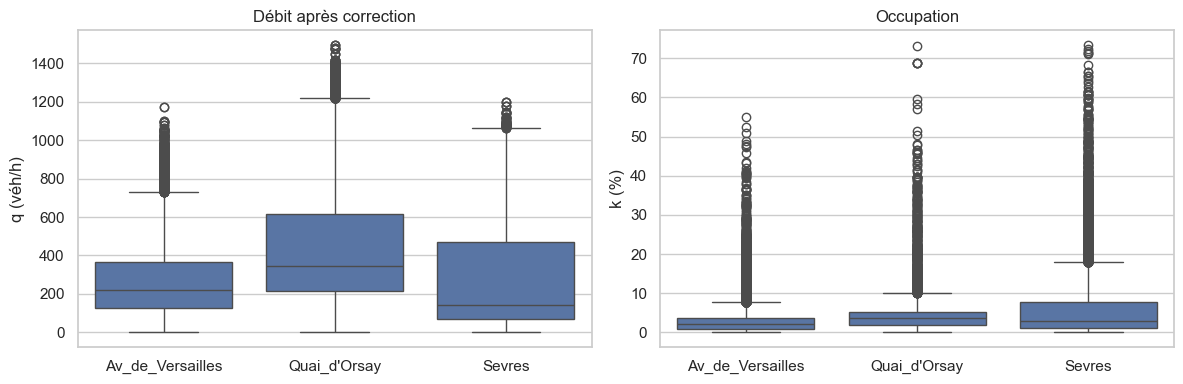

In [57]:
SEUIL_Q = 2000   # véh/h : bien au-dessus du plus fort débit plausible (1 497)

impossible = df["q"] > SEUIL_Q
print(f"{impossible.sum()} valeurs > {SEUIL_Q} véh/h, capteurs : {df.loc[impossible, 'iu_ac'].unique().tolist()}")
print(f"Débit max hors de ces valeurs : {df.loc[~impossible, 'q'].max():.0f} véh/h")
df.loc[impossible, "q"] = np.nan    # on invalide la mesure, on garde la ligne

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="libelle", y="q", ax=axes[0])
axes[0].set(title="Débit après correction", xlabel="", ylabel="q (véh/h)")
sns.boxplot(data=df, x="libelle", y="k", ax=axes[1])
axes[1].set(title="Occupation", xlabel="", ylabel="k (%)")
plt.tight_layout()
plt.show()

## statistiques par tronçon

In [58]:
# Un débit recopié sur plusieurs capteurs ne doit être compté qu'une fois
q_unique = df.dropna(subset=["q"]).drop_duplicates(["groupe_q", "t_1h"])

agg = ["mean", "median", "std", "max"]
par_axe = pd.concat({
    "q (séries uniques)": q_unique.groupby("libelle", observed=True)["q"].agg(agg),
    "k (tous les capteurs)": df.groupby("libelle", observed=True)["k"].agg(agg),
}, axis=1).round(1)
display(par_axe)

# Part du temps hors Fluide et Bloqué, par tronçon
etats = df.groupby("libelle", observed=True)["etat_trafic"]
pd.DataFrame({
    "% hors Fluide": etats.apply(lambda s: (s != "Fluide").mean() * 100).round(1),
    "% Bloqué": etats.apply(lambda s: (s == "Bloqué").mean() * 100).round(2),
})

q (séries uniques)                        \
                               mean median    std     max   
libelle                                                     
Av_de_Versailles              280.4  236.0  190.6  1171.0   
Quai_d'Orsay                  431.7  342.0  320.4  1497.0   
Sevres                        310.1  164.0  287.8  1200.0   

                 k (tous les capteurs)                    
                                  mean median  std   max  
libelle                                                   
Av_de_Versailles                   2.9    2.1  3.1  55.0  
Quai_d'Orsay                       3.8    3.7  2.8  73.0  
Sevres                             5.5    3.0  7.0  73.4

,% hors Fluide,% Bloqué
libelle,,
Av_de_Versailles,1.7,0.01
Quai_d'Orsay,0.7,0.02
Sevres,8.9,0.24


In [59]:
# 3 heures les plus congestionnées par tronçon (occupation médiane, jours ouvrés)
pointe = (df[df["weekend"] == "non"]
          .groupby(["libelle", "heure"], observed=True)["k"].median()
          .groupby(level=0, observed=True).nlargest(3)
          .droplevel(0).round(1))
display(pointe)

# Moment le plus chargé de chaque tronçon
idx_max = df.groupby("libelle", observed=True)["k"].idxmax()
df.loc[idx_max, ["libelle", "iu_ac", "t_1h_paris", "q", "k", "etat_trafic"]]

libelle           heure
Av_de_Versailles  9        4.2
                  19       3.8
                  10       3.7
Quai_d'Orsay      20       5.2
                  19       5.1
                  18       5.0
Sevres            18       8.6
                  19       8.4
                  17       8.2
Name: k, dtype: float64

,libelle,iu_ac,t_1h_paris,q,k,etat_trafic
74637,Av_de_Versailles,4717,2026-06-18 20:00:00+02:00,267.0,55.02111,Bloqué
5747,Quai_d'Orsay,318,2026-05-31 00:00:00+02:00,558.0,73.02278,Bloqué
120301,Sevres,5589,2026-06-04 20:00:00+02:00,534.0,73.43500,Bloqué


Heures les plus congestionnées en jours ouvrés (occupation médiane) : Av_de_Versailles 9 h,
19 h et 10 h (4,2 / 3,8 / 3,7 %) ; Quai_d'Orsay 20 h, 19 h et 18 h (5,2 / 5,1 / 5,0 %) ;
Sevres 18 h, 19 h et 17 h (8,6 / 8,4 / 8,2 %). La pointe du soir domine sur les trois axes.

Pics maximaux d'occupation, tous à l'état Bloqué :
- Av_de_Versailles : capteur 4717, le 18/06/2026 à 20 h, k = 55,0 % (q = 267 véh/h) ;
- Quai_d'Orsay : capteur 318, le 31/05/2026 à 00 h, k = 73,0 % (q = 558 véh/h) ;
- Sevres : capteur 5589, le 04/06/2026 à 20 h, k = 73,4 % (q = 534 véh/h).
Les pics de Versailles et de Sèvres tombent en soirée, cohérent avec la pointe du soir.
Celui du Quai d'Orsay a lieu un dimanche à minuit, hors de toute heure de pointe : événement
ponctuel ou défaillance du capteur, à vérifier avant de conclure.

In [60]:
df.to_csv(SORTIE, index=False)
print(df.shape, "->", SORTIE)

(142087, 18) -> C:\Users\zBalde\Desktop\Aivancity_M2\analyse_et_transfo_officiel\notebooks\data\processed\comptages_features.csv
